In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Dataset paths
IMAGE_DIR = (
    "/content/drive/MyDrive/MAJOR_PROJECT/data/"
    "chest-xray-masks-and-labels/Lung Segmentation/CXR_png"
)
MASK_DIR = (
    "/content/drive/MyDrive/MAJOR_PROJECT/data/"
    "chest-xray-masks-and-labels/Lung Segmentation/masks"
)
SPLIT_DIR = "/content/drive/MyDrive/MAJOR_PROJECT/splits"

# Output directory
RESULTS_DIR = (
    "/content/drive/MyDrive/MAJOR_PROJECT/Attention-Unet"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    RESULTS_DIR, "best_attention_unet.pth"
)

# Training settings
IMAGE_SIZE = (512, 512)
BATCH_SIZE = 4
MAX_EPOCHS = 30
PATIENCE = 7
LEARNING_RATE = 1e-4
SEED = 42

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Image directory exists:", os.path.isdir(IMAGE_DIR))
print("Mask directory exists:", os.path.isdir(MASK_DIR))
print("Split directory exists:", os.path.isdir(SPLIT_DIR))
print("Results directory:", RESULTS_DIR)

assert os.path.isdir(IMAGE_DIR), "Image directory not found."
assert os.path.isdir(MASK_DIR), "Mask directory not found."


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Device: cuda
Image directory exists: True
Mask directory exists: True
Split directory exists: True
Results directory: /content/drive/MyDrive/MAJOR_PROJECT/Attention-Unet


In [ ]:

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

# --------------------------------------------------
# 1. INDEX X-RAY IMAGES
# --------------------------------------------------
valid_extensions = (".png", ".jpg", ".jpeg")

image_files = {
    os.path.splitext(f)[0]: os.path.join(IMAGE_DIR, f)
    for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(valid_extensions)
}

# --------------------------------------------------
# 2. INDEX MASKS
# Remove "_mask" suffix to match the X-ray filename
# --------------------------------------------------
mask_files = {}

for filename in os.listdir(MASK_DIR):
    if not filename.lower().endswith(valid_extensions):
        continue

    stem = os.path.splitext(filename)[0]

    if stem.endswith("_mask"):
        stem = stem[:-5]

    mask_files[stem] = os.path.join(MASK_DIR, filename)

# --------------------------------------------------
# 3. CREATE VALID IMAGE-MASK PAIRS
# Each item: (stem, image_path, mask_path)
# --------------------------------------------------
all_pairs = []

for stem in sorted(image_files):
    if stem in mask_files:
        all_pairs.append(
            (stem, image_files[stem], mask_files[stem])
        )

print("X-ray images found:", len(image_files))
print("Masks found:", len(mask_files))
print("Valid image-mask pairs:", len(all_pairs))

assert len(all_pairs) > 0, (
    "No matching image-mask pairs found. Check IMAGE_DIR and MASK_DIR."
)

pairs_by_name = {
    stem: (img, mask)
    for stem, img, mask in all_pairs
}


# --------------------------------------------------
# 4. READ EXISTING SPLIT FILES
# Supports:
# image.png,mask.png
# image.png
# Full paths are also supported.
# --------------------------------------------------
def read_split(filename):
    path = os.path.join(SPLIT_DIR, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(
            f"Split file not found: {path}"
        )

    selected = []
    missing = []

    with open(path, "r", encoding="utf-8-sig") as file:
        for line_number, line in enumerate(file, start=1):
            line = line.strip()

            if not line:
                continue

            # Remove optional quotes around CSV fields
            parts = [
                part.strip().strip('"').strip("'")
                for part in line.split(",")
            ]

            # Handle an optional CSV header
            if (
                line_number == 1
                and len(parts) >= 2
                and parts[0].lower() in {
                    "image", "image_name", "image_file",
                    "image_filename", "xray"
                }
            ):
                continue

            # First field is the X-ray filename/path
            image_name = os.path.basename(
                parts[0].replace("\\", "/")
            )
            stem = os.path.splitext(image_name)[0]

            # If a mask filename is provided, verify it matches
            if len(parts) >= 2 and parts[1]:
                mask_name = os.path.basename(
                    parts[1].replace("\\", "/")
                )
                mask_stem = os.path.splitext(mask_name)[0]

                if mask_stem.endswith("_mask"):
                    mask_stem = mask_stem[:-5]

                if mask_stem != stem:
                    missing.append(
                        f"Line {line_number}: image '{image_name}' "
                        f"does not match mask '{mask_name}'"
                    )
                    continue

            # Support image filenames with or without extensions
            if stem.endswith("_mask"):
                stem = stem[:-5]

            if stem in pairs_by_name:
                img, mask = pairs_by_name[stem]
                selected.append((stem, img, mask))
            else:
                missing.append(
                    f"Line {line_number}: {line.strip()}"
                )

    if missing:
        raise ValueError(
            f"{len(missing)} entries in {filename} could not be matched. "
            f"Examples: {missing[:5]}. "
            "Check the filenames and image/mask folders."
        )

    # Ensure there are no duplicate images in this split
    selected_names = [item[0] for item in selected]

    if len(set(selected_names)) != len(selected_names):
        raise ValueError(
            f"Duplicate entries found in {filename}."
        )

    print(f"Loaded {len(selected)} pairs from {filename}")
    return selected


# --------------------------------------------------
# 5. LOAD EXISTING SPLITS OR CREATE NEW ONES
# --------------------------------------------------
split_names = [
    "train_files.txt",
    "val_files.txt",
    "test_files.txt"
]

split_paths = [
    os.path.join(SPLIT_DIR, name)
    for name in split_names
]

if all(os.path.isfile(path) for path in split_paths):
    print("\nLoading your existing saved splits...")

    train_pairs = read_split("train_files.txt")
    val_pairs = read_split("val_files.txt")
    test_pairs = read_split("test_files.txt")

else:
    print(
        "\nNot all split files exist. "
        "Creating and saving a reproducible split."
    )

    os.makedirs(SPLIT_DIR, exist_ok=True)

    rng = np.random.default_rng(SEED)
    indices = rng.permutation(len(all_pairs))

    n_train = int(0.8 * len(all_pairs))
    n_val = int(0.1 * len(all_pairs))

    train_pairs = [
        all_pairs[i] for i in indices[:n_train]
    ]
    val_pairs = [
        all_pairs[i]
        for i in indices[n_train:n_train + n_val]
    ]
    test_pairs = [
        all_pairs[i]
        for i in indices[n_train + n_val:]
    ]

    for filename, pairs in zip(
        split_names,
        [train_pairs, val_pairs, test_pairs]
    ):
        with open(
            os.path.join(SPLIT_DIR, filename),
            "w",
            encoding="utf-8"
        ) as file:
            # Save image and mask filenames as CSV fields
            for stem, image_path, mask_path in pairs:
                file.write(
                    f"{os.path.basename(image_path)},"
                    f"{os.path.basename(mask_path)}\n"
                )


# --------------------------------------------------
# 6. VERIFY SPLITS DO NOT OVERLAP
# --------------------------------------------------
train_names = {p[0] for p in train_pairs}
val_names = {p[0] for p in val_pairs}
test_names = {p[0] for p in test_pairs}

assert not (train_names & val_names), (
    "Training and validation sets overlap."
)
assert not (train_names & test_names), (
    "Training and test sets overlap."
)
assert not (val_names & test_names), (
    "Validation and test sets overlap."
)

assert len(train_pairs) + len(val_pairs) + len(test_pairs) <= len(all_pairs), (
    "Split sizes exceed the number of valid pairs."
)

print("\nSplit verification complete.")
print("Training pairs:", len(train_pairs))
print("Validation pairs:", len(val_pairs))
print("Test pairs:", len(test_pairs))


# --------------------------------------------------
# 7. DATASET CLASS
# --------------------------------------------------
class LungSegmentationDataset(Dataset):
    def __init__(self, pairs, augment=False):
        self.pairs = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, index):
        _, image_path, mask_path = self.pairs[index]

        image = Image.open(image_path).convert("L")
        mask = Image.open(mask_path).convert("L")

        image = image.resize(
            IMAGE_SIZE, Image.Resampling.BILINEAR
        )
        mask = mask.resize(
            IMAGE_SIZE, Image.Resampling.NEAREST
        )

        image = np.asarray(image, dtype=np.float32) / 255.0
        mask = np.asarray(mask, dtype=np.uint8)

        # Lung pixels = 1; background = 0
        mask = (mask > 127).astype(np.float32)

        # Apply the same horizontal flip to both
        if self.augment and random.random() < 0.5:
            image = np.fliplr(image).copy()
            mask = np.fliplr(mask).copy()

        # Grayscale X-ray -> three channels
        image = np.stack([image, image, image], axis=0)
        mask = mask[np.newaxis, :, :]

        return (
            torch.from_numpy(image).float(),
            torch.from_numpy(mask).float()
        )


# --------------------------------------------------
# 8. CREATE DATASETS AND DATA LOADERS
# --------------------------------------------------
train_dataset = LungSegmentationDataset(
    train_pairs, augment=True
)
val_dataset = LungSegmentationDataset(
    val_pairs, augment=False
)
test_dataset = LungSegmentationDataset(
    test_pairs, augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)


# --------------------------------------------------
# 9. VERIFY DATA LOADERS
# --------------------------------------------------
images, masks = next(iter(train_loader))

print("\nData loaders ready!")
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Image batch shape:", images.shape)
print("Mask batch shape:", masks.shape)


X-ray images found: 289
Masks found: 704
Valid image-mask pairs: 242

Loading your existing saved splits...
Loaded 193 pairs from train_files.txt
Loaded 24 pairs from val_files.txt
Loaded 25 pairs from test_files.txt

Split verification complete.
Training pairs: 193
Validation pairs: 24
Test pairs: 25

Data loaders ready!
Training: 193
Validation: 24
Testing: 25
Image batch shape: torch.Size([4, 3, 512, 512])
Mask batch shape: torch.Size([4, 1, 512, 512])


In [ ]:

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, 3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels, out_channels, 3,
                padding=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class AttentionGate(nn.Module):
    def __init__(self, gate_channels, skip_channels, inter_channels):
        super().__init__()

        self.gate_conv = nn.Sequential(
            nn.Conv2d(
                gate_channels, inter_channels, 1, bias=False
            ),
            nn.BatchNorm2d(inter_channels)
        )

        self.skip_conv = nn.Sequential(
            nn.Conv2d(
                skip_channels, inter_channels, 1, bias=False
            ),
            nn.BatchNorm2d(inter_channels)
        )

        self.score = nn.Sequential(
            nn.ReLU(inplace=True),
            nn.Conv2d(inter_channels, 1, 1),
            nn.Sigmoid()
        )

    def forward(self, gate, skip):
        gate = self.gate_conv(gate)
        skip_projected = self.skip_conv(skip)

        gate = F.interpolate(
            gate,
            size=skip_projected.shape[2:],
            mode="bilinear",
            align_corners=False
        )

        attention_map = self.score(gate + skip_projected)

        # Apply attention weights to encoder features
        return skip * attention_map


class AttentionUNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, base=16):
        super().__init__()

        self.pool = nn.MaxPool2d(2)

        # Encoder
        self.enc1 = ConvBlock(in_channels, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 8)

        # Bottleneck
        self.bottleneck = ConvBlock(base * 8, base * 16)

        # Attention gates for skip connections
        self.att4 = AttentionGate(base * 16, base * 8, base * 4)
        self.att3 = AttentionGate(base * 8, base * 4, base * 2)
        self.att2 = AttentionGate(base * 4, base * 2, base)
        self.att1 = AttentionGate(base * 2, base, base)

        # Decoder
        self.dec4 = ConvBlock(base * 16 + base * 8, base * 8)
        self.dec3 = ConvBlock(base * 8 + base * 4, base * 4)
        self.dec2 = ConvBlock(base * 4 + base * 2, base * 2)
        self.dec1 = ConvBlock(base * 2 + base, base)

        self.output_layer = nn.Conv2d(base, out_channels, 1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder with attention-weighted skip connections
        s4 = self.att4(b, e4)
        d4 = F.interpolate(
            b, size=s4.shape[2:],
            mode="bilinear", align_corners=False
        )
        d4 = self.dec4(torch.cat([d4, s4], dim=1))

        s3 = self.att3(d4, e3)
        d3 = F.interpolate(
            d4, size=s3.shape[2:],
            mode="bilinear", align_corners=False
        )
        d3 = self.dec3(torch.cat([d3, s3], dim=1))

        s2 = self.att2(d3, e2)
        d2 = F.interpolate(
            d3, size=s2.shape[2:],
            mode="bilinear", align_corners=False
        )
        d2 = self.dec2(torch.cat([d2, s2], dim=1))

        s1 = self.att1(d2, e1)
        d1 = F.interpolate(
            d2, size=s1.shape[2:],
            mode="bilinear", align_corners=False
        )
        d1 = self.dec1(torch.cat([d1, s1], dim=1))

        return self.output_layer(d1)


# Create a fresh Attention U-Net model
model = AttentionUNet(
    in_channels=3,
    out_channels=1,
    base=16
).to(device)

with torch.no_grad():
    sample = torch.randn(1, 3, 512, 512, device=device)
    output = model(sample)

print("Attention U-Net created successfully.")
print("Output shape:", output.shape)

del sample, output


Attention U-Net created successfully.
Output shape: torch.Size([1, 1, 512, 512])


In [ ]:

class DiceLoss(nn.Module):
    def forward(self, logits, targets):
        probabilities = torch.sigmoid(logits)

        intersection = (probabilities * targets).sum(dim=(1, 2, 3))
        denominator = (
            probabilities.sum(dim=(1, 2, 3))
            + targets.sum(dim=(1, 2, 3))
        )

        dice = (
            (2 * intersection + 1e-6)
            / (denominator + 1e-6)
        )

        return 1 - dice.mean()


bce_loss = nn.BCEWithLogitsLoss()
dice_loss = DiceLoss()


def combined_loss(logits, masks):
    return bce_loss(logits, masks) + dice_loss(logits, masks)


optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3
)


def train_one_epoch(model, loader):
    model.train()

    total_loss = 0.0
    total_images = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = combined_loss(logits, masks)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

    return total_loss / max(total_images, 1)


@torch.no_grad()
def validate_one_epoch(model, loader):
    model.eval()

    total_loss = 0.0
    total_images = 0
    tp = fp = fn = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        loss = combined_loss(logits, masks)

        total_loss += loss.item() * images.size(0)
        total_images += images.size(0)

        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        tp += (predictions & targets).sum().item()
        fp += (predictions & ~targets).sum().item()
        fn += (~predictions & targets).sum().item()

    dice = (2 * tp) / (2 * tp + fp + fn + 1e-8)
    iou = tp / (tp + fp + fn + 1e-8)

    return {
        "loss": total_loss / max(total_images, 1),
        "dice": dice,
        "iou": iou
    }


print("Loss, optimizer, scheduler, and functions are ready.")


Loss, optimizer, scheduler, and functions are ready.


In [ ]:

best_val_dice = -1.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": []
}

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss = train_one_epoch(model, train_loader)
    val_metrics = validate_one_epoch(model, val_loader)

    val_dice = val_metrics["dice"]
    scheduler.step(val_dice)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_metrics["loss"])
    history["val_dice"].append(val_dice)
    history["val_iou"].append(val_metrics["iou"])

    print(
        f"Epoch [{epoch}/{MAX_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Dice: {val_dice:.4f} | "
        f"Val IoU: {val_metrics['iou']:.4f}"
    )

    if val_dice > best_val_dice:
        best_val_dice = val_dice
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "val_dice": val_dice,
            "val_iou": val_metrics["iou"]
        }, BEST_MODEL_PATH)

        print("  Best model checkpoint saved.")
    else:
        epochs_without_improvement += 1
        print(
            "  No improvement for",
            epochs_without_improvement,
            "epoch(s)."
        )

    # Save progress after each epoch
    pd.DataFrame(history).to_csv(
        os.path.join(RESULTS_DIR, "training_history.csv"),
        index=False
    )

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping: validation Dice has plateaued.")
        break

print("\nTraining finished.")
print("Best validation Dice:", round(best_val_dice, 4))
print("Best model saved at:", BEST_MODEL_PATH)


Epoch [1/30] | Train Loss: 1.0238 | Val Loss: 1.2466 | Val Dice: 0.2603 | Val IoU: 0.1496
  Best model checkpoint saved.
Epoch [2/30] | Train Loss: 0.8616 | Val Loss: 0.8411 | Val Dice: 0.9243 | Val IoU: 0.8592
  Best model checkpoint saved.
Epoch [3/30] | Train Loss: 0.8340 | Val Loss: 0.8044 | Val Dice: 0.9377 | Val IoU: 0.8828
  Best model checkpoint saved.
Epoch [4/30] | Train Loss: 0.8094 | Val Loss: 0.7906 | Val Dice: 0.9383 | Val IoU: 0.8838
  Best model checkpoint saved.
Epoch [5/30] | Train Loss: 0.7893 | Val Loss: 0.7775 | Val Dice: 0.9365 | Val IoU: 0.8805
  No improvement for 1 epoch(s).
Epoch [6/30] | Train Loss: 0.7695 | Val Loss: 0.7477 | Val Dice: 0.9467 | Val IoU: 0.8989
  Best model checkpoint saved.
Epoch [7/30] | Train Loss: 0.7523 | Val Loss: 0.7386 | Val Dice: 0.9426 | Val IoU: 0.8914
  No improvement for 1 epoch(s).
Epoch [8/30] | Train Loss: 0.7361 | Val Loss: 0.7252 | Val Dice: 0.9461 | Val IoU: 0.8978
  No improvement for 2 epoch(s).
Epoch [9/30] | Train Loss:

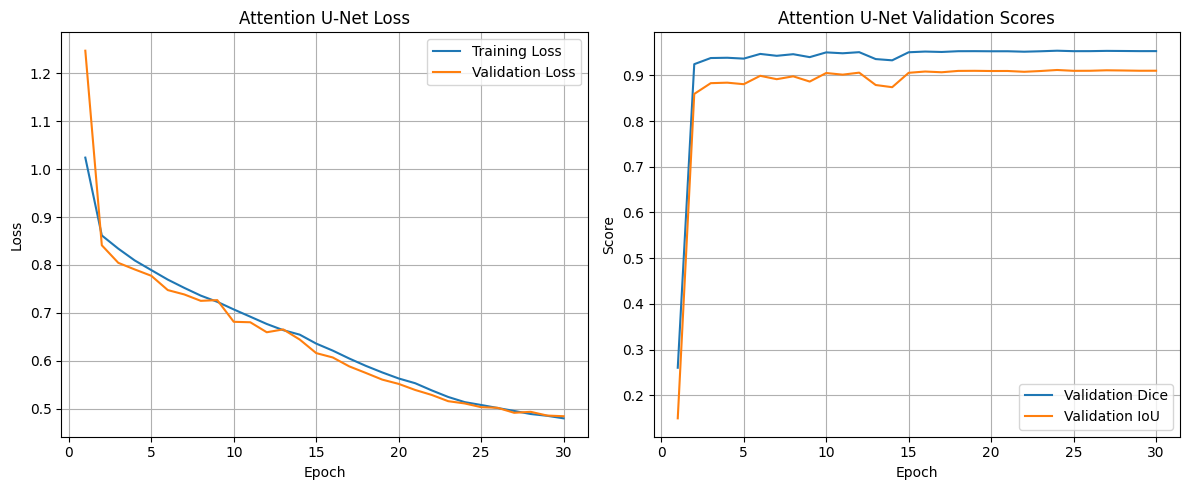

In [ ]:

epochs = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, history["train_loss"], label="Training Loss")
plt.plot(epochs, history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Attention U-Net Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, history["val_dice"], label="Validation Dice")
plt.plot(epochs, history["val_iou"], label="Validation IoU")
plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Attention U-Net Validation Scores")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:

checkpoint = torch.load(BEST_MODEL_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()


@torch.no_grad()
def evaluate_test(model, loader):
    model.eval()
    tp = fp = fn = tn = 0

    for images, masks in loader:
        images = images.to(device)
        masks = masks.to(device)

        logits = model(images)
        predictions = torch.sigmoid(logits) >= 0.5
        targets = masks >= 0.5

        tp += (predictions & targets).sum().item()
        fp += (predictions & ~targets).sum().item()
        fn += (~predictions & targets).sum().item()
        tn += (~predictions & ~targets).sum().item()

    return {
        "Dice": (2 * tp) / (2 * tp + fp + fn + 1e-8),
        "IoU": tp / (tp + fp + fn + 1e-8),
        "Precision": tp / (tp + fp + 1e-8),
        "Recall": tp / (tp + fn + 1e-8),
        "Pixel Accuracy": (tp + tn) / (tp + tn + fp + fn + 1e-8)
    }


test_results = evaluate_test(model, test_loader)

print("Best checkpoint epoch:", checkpoint["epoch"])
print("\nAttention U-Net — Test Results")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

# Save final test metrics
pd.DataFrame([test_results]).to_csv(
    os.path.join(RESULTS_DIR, "test_results.csv"),
    index=False
)


Best checkpoint epoch: 24

Attention U-Net — Test Results
Dice: 0.9556
IoU: 0.9150
Precision: 0.9773
Recall: 0.9349
Pixel Accuracy: 0.9789


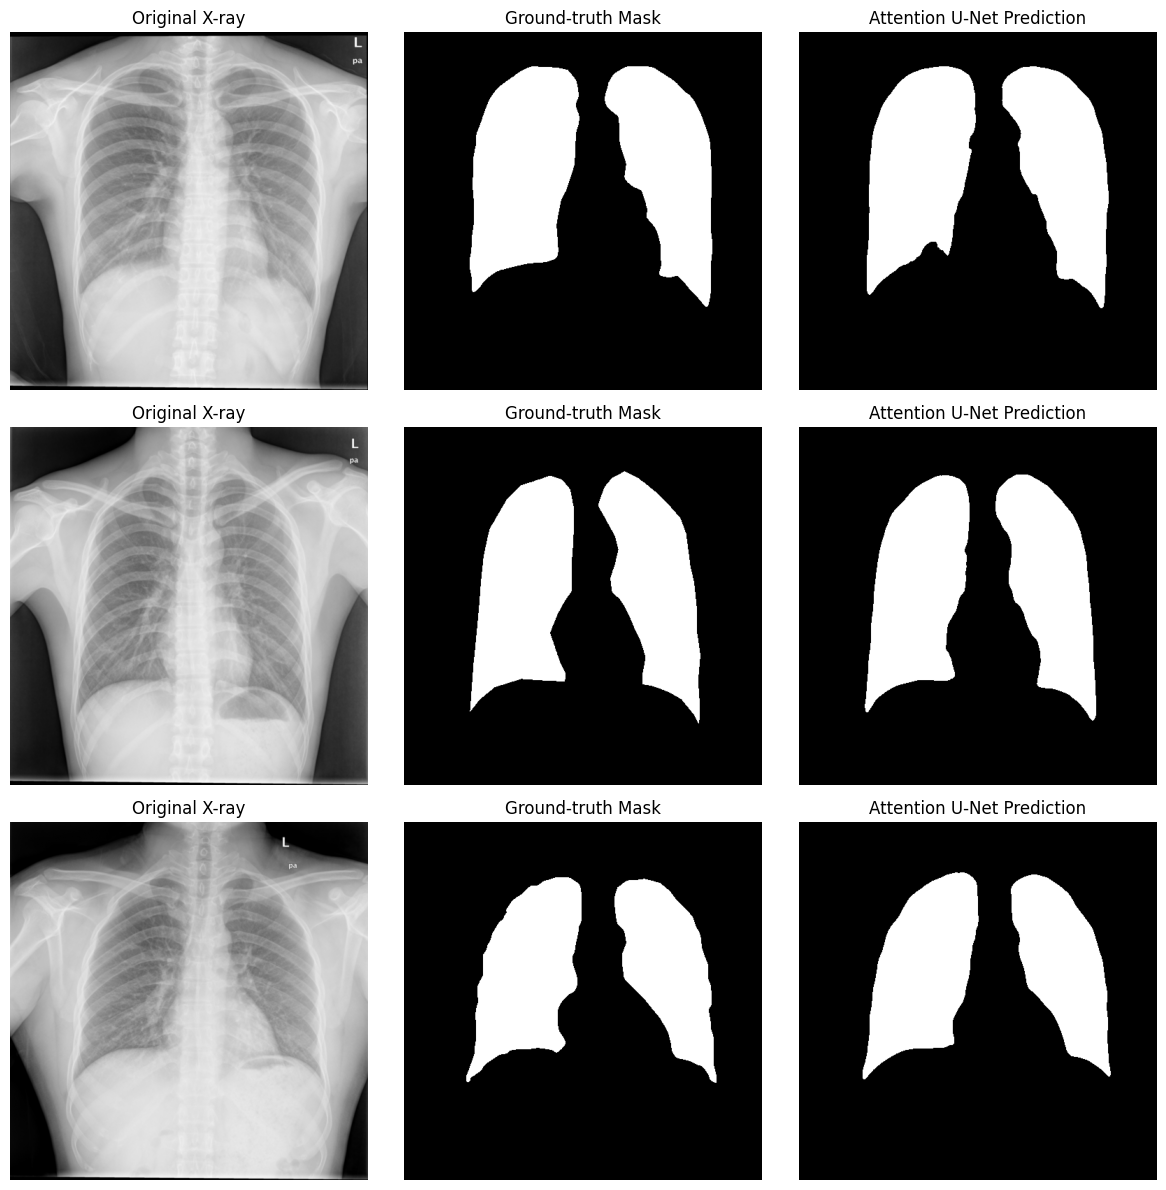

In [ ]:

@torch.no_grad()
def show_predictions(model, loader, number_of_images=3):
    model.eval()
    images, masks = next(iter(loader))

    images = images.to(device)
    logits = model(images)
    predictions = (torch.sigmoid(logits) >= 0.5).float()

    n = min(number_of_images, images.size(0))

    fig, axes = plt.subplots(n, 3, figsize=(12, 4 * n))

    if n == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(n):
        image = images[i, 0].cpu().numpy()
        true_mask = masks[i, 0].cpu().numpy()
        predicted_mask = predictions[i, 0].cpu().numpy()

        axes[i, 0].imshow(image, cmap="gray")
        axes[i, 0].set_title("Original X-ray")

        axes[i, 1].imshow(true_mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 1].set_title("Ground-truth Mask")

        axes[i, 2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1)
        axes[i, 2].set_title("Attention U-Net Prediction")

        for ax in axes[i]:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


show_predictions(model, test_loader, number_of_images=3)
